# Detecting Duplicate Questions with Machine Learning
Portfolio edition of a university text-processing project.
Results below are saved outputs, not a new training run. Comparison commentary has been aligned with those outputs.



## Objectives of this assignment

In this assignment, you will work on the Quora Question Pairs (QQP) datset detailed below. The first two tasks will help you get familiar with the data, and the remaining requires you to implement deep neural networks.


**About the Quora Question Pairs (QQP) Dataset**

Description: A large dataset of 400k+ question pairs from Quora, labeled whether they are duplicates (semantically the same) or not. It features informal, noisy text with class imbalance, hard positives (low lexical overlap) and hard negatives (high overlap, different meaning). QQP is practically relevant for deduplicating FAQs, search, and support systems. Working on QQP builds transferable skills, such as text preprocessing, model comparison, threshold tuning, error analysis, and deployment-minded reasoning about real applications.

In [29]:
import sys
!{sys.executable} -m pip install "torchvision" --upgrade -q

In [30]:
import sys
print(sys.executable)

In [31]:
# Fix torch/torchvision version mismatch
try:
    import torch._library.fake_impl as _fi
    _orig = _fi.FakeImplHolder.register
    def _safe(self, func, source=None, lib=None, allow_override=False):
        try:
            return _orig(self, func, source=source, lib=lib, allow_override=allow_override)
        except RuntimeError:
            return func
    _fi.FakeImplHolder.register = _safe
except Exception:
    pass


**Get familiar with the dataset**

In [32]:
!pip -q install datasets    # Install the datasets package to access the dataset
# add the packages you used, and specify the verion you installed

from datasets import load_dataset
import numpy as np

import random
from collections import Counter

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from transformers import BertTokenizer, BertForSequenceClassification
from torch.optim import AdamW
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.stem import PorterStemmer
from nltk.util import bigrams as nltk_bigrams
from nltk.tokenize import sent_tokenize, word_tokenize

# --- random seed ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [33]:
# 1) Load QQP
ds = load_dataset("glue", "qqp")

# Use validation set as our test; optionally create a smaller train subset for speed
train_ds = ds["train"]
eval_ds  = ds["validation"]

q1_tr = list(train_ds["question1"])
q2_tr = list(train_ds["question2"])
y_tr  = np.array(train_ds["label"])

q1_te = list(eval_ds["question1"])
q2_te = list(eval_ds["question2"])
y_te  = np.array(eval_ds["label"])

print(f"Full QQP train size : {len(train_ds):,}")
print(f"Full QQP val   size : {len(eval_ds):,}")

Full QQP train size : 363,846
Full QQP val   size : 40,430


---

### Task 1. What is the top-5 common NOUN in the question1 and question2, respectively? (5 marks)

Write codes that returns the top-5 common NOUN in the questions. To find the part of speech, use NLTK's "Universal" tag set. You may need to use NLTK's `sent_tokenize` and `word_tokenize` to get words. The function returns a list that is descendingly sorted according to freqency, e.g. [(noun1, 22), (noun2, 10), ...].
<!-- To produce the correct results, the function must do this.  -->
Hint: The following steps will produce the correct results:

- Concatenate all questions together.
- Use the NLTK libraries to find the tokens and the stems.
- Use NLTK's sentence tokeniser before NLTK's word tokeniser.
- Use NLTK's part of speech tagger, using the "Universal" tagset.
- Use NLTK's `pos_tag_sents` instead of `pos_tag`.

Marking Criteria: 
- 2.5 marks for the correct codes and results of each column, namely question1 and question2 columns.




In [34]:
def top5_nouns(questions):
    combined_text = " ".join(questions)

    sentences = nltk.sent_tokenize(combined_text)
    tokenised_sents = [nltk.word_tokenize(s) for s in sentences]

    tagged_sents = nltk.pos_tag_sents(tokenised_sents, tagset='universal')

    nouns = [word.lower()
             for sentence in tagged_sents
             for (word, tag) in sentence
             if tag == 'NOUN']

    return Counter(nouns).most_common(5)


print("Top-5 most common nouns in question1:")
top5_nouns_q1 = top5_nouns(q1_tr)
print(top5_nouns_q1)

print("\nTop-5 most common nouns in question2:")
top5_nouns_q2 = top5_nouns(q2_tr)
print(top5_nouns_q2)


Top-5 most common nouns in question1:
[('india', 12699), ('people', 11449), ('way', 7695), ('quora', 7678), ('life', 6774)]

Top-5 most common nouns in question2:
[('india', 13480), ('people', 12231), ('way', 8615), ('quora', 7967), ('life', 7258)]


---

### Task 2. What are the top-5 common stem 2-grams and non-stem 2-grams for question1 and question2, respectively? (5 marks)

Write codes that returns the top-5 most frequent 2-grams (bigrams) of stemmed and non-stemmed tokens along with their normalized frequency from the question1 and question2 columns of the QQP dataset. The output should be in descending order of frequency, **with frequencies normalized by the total number of bigrams (rounded to 4 decimal places)**, e.g., `[(('what', 'is'), 0.0105), (('what', 'are'), 0.0053), ...]`.

<!-- To produce the correct results, the function must do this: -->

Hint: The following steps will produce the correct results:

- Concatenate all questions together.
- Use NLTK's sentence tokeniser before NLTK's word tokeniser.
- Use the NLTK libraries to find the tokens and the stems.
- Use NLTK's Porter stemmer to get the root words.
- Round normalized frequency to 4 precision after the decimal point.
- When computing bigrams, do not consider words that are in different sentences. For example, if we have this text: `Sentence 1. And sentence 2.` the bigrams are: `('Sentence','1'), ('1','.'), ('.','And'), ('And','sentence')`, etc. Note that the following would not be a valid bigram, since the punctuation mark and the word "And" are in different sentences: `('.','And')`.

Marking Criteria: 
- 2.5 marks for the correct codes and restuls of each column, namely question1 and question2 columns.

In [ ]:
def get_top_bigrams(questions, stemmed=False):
    stemmer = PorterStemmer()

    combined_text = " ".join(questions)

    sentences = sent_tokenize(combined_text)

    all_bigrams = []
    for sentence in sentences:
        tokens = word_tokenize(sentence)

        if stemmed:
            tokens = [stemmer.stem(tok) for tok in tokens]

        sentence_bigrams = list(nltk_bigrams(tokens))
        all_bigrams.extend(sentence_bigrams)

    bigram_counts = Counter(all_bigrams)
    total = sum(bigram_counts.values())

    top = [
        (bg, round(cnt / total, 4))
        for bg, cnt in bigram_counts.most_common(5)
    ]
    return top


print("Question1 | Non-stemmed top-5 bigrams:")
print(get_top_bigrams(q1_tr, stemmed=False))

print("\nQuestion1 | Stemmed top-5 bigrams:")
print(get_top_bigrams(q1_tr, stemmed=True))

print("\nQuestion2 | Non-stemmed top-5 bigrams:")
print(get_top_bigrams(q2_tr, stemmed=False))

print("\nQuestion2 | Stemmed top-5 bigrams:")
print(get_top_bigrams(q2_tr, stemmed=True))
    

Question1 | Non-stemmed top-5 bigrams:
[(('What', 'is'), 0.0125), (('is', 'the'), 0.0108), (('What', 'are'), 0.01), (('How', 'do'), 0.008), (('the', 'best'), 0.0064)]

Question1 | Stemmed top-5 bigrams:
[(('what', 'is'), 0.0128), (('is', 'the'), 0.0112), (('what', 'are'), 0.0102), (('how', 'do'), 0.0084), (('can', 'i'), 0.0067)]

Question2 | Non-stemmed top-5 bigrams:
[(('What', 'is'), 0.012), (('is', 'the'), 0.0104), (('What', 'are'), 0.0096), (('How', 'do'), 0.0081), (('the', 'best'), 0.0066)]

Question2 | Stemmed top-5 bigrams:L
[(('what', 'is'), 0.0123), (('is', 'the'), 0.0108), (('what', 'are'), 0.0098), (('how', 'do'), 0.0085), (('can', 'i'), 0.0068)]


---

### Task 3. Naïve Bayes Classifier (5.5 marks)

The QQR dataset contains pairs of questions with labels indicating whether the two questions are semantically duplicate (1) or not (0).

1. Using a Bag-of-Words representation, train a Naïve Bayes classifier to predict duplicates. (2 marks)

1. Report accuracy, precision, and recall on the test set. (1.5 marks)

1. Inspect your confusion matrix. Identify one type of error (false positive or false negative) that dominates. Suggest a possible reason for this pattern based on the dataset. (2 mark)

In [36]:
# From now on, you are allowed to use a subset of the dataset which requires less computing resources.
# Note that you have to use the same subset for the following coding tasks, which ensure fairness when comparing performance across different models.

Ntrain = 1000
Ntest = 100
ds = load_dataset("glue", "qqp")

# Use validation set as our test; optionally create a smaller train subset for speed
train_ds = ds["train"].select(range(Ntrain))
eval_ds  = ds["validation"].select(range(Ntest))

def combine(batch):
    return {"text": batch["question1"] + " " + batch["question2"]}

train_texts  = [ex["question1"] + " " + ex["question2"] for ex in train_ds]
train_labels = [ex["label"] for ex in train_ds]

test_texts   = [ex["question1"] + " " + ex["question2"] for ex in eval_ds]
test_labels  = [ex["label"] for ex in eval_ds]

# Update q1/q2/y variables so Task 4 and Task 5 also use the reduced subset
q1_tr = [ex["question1"] for ex in train_ds]
q2_tr = [ex["question2"] for ex in train_ds]
y_tr  = np.array([ex["label"] for ex in train_ds])

q1_te = [ex["question1"] for ex in eval_ds]
q2_te = [ex["question2"] for ex in eval_ds]
y_te  = np.array([ex["label"] for ex in eval_ds])


In [37]:
vectorizer = CountVectorizer()
X_train = vectorizer.fit_transform(train_texts)
X_test  = vectorizer.transform(test_texts)

nb = MultinomialNB()
nb.fit(X_train, train_labels)

y_pred = nb.predict(X_test)
y_true = test_labels

accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall    = recall_score(y_true, y_pred, zero_division=0)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")

Accuracy : 0.6600
Precision: 0.4286
Recall   : 0.4000



Confusion Matrix (rows=true, cols=predicted):
               Pred 0   Pred 1
True 0 (non-dup):    54       16
True 1 (dup)    :    18       12


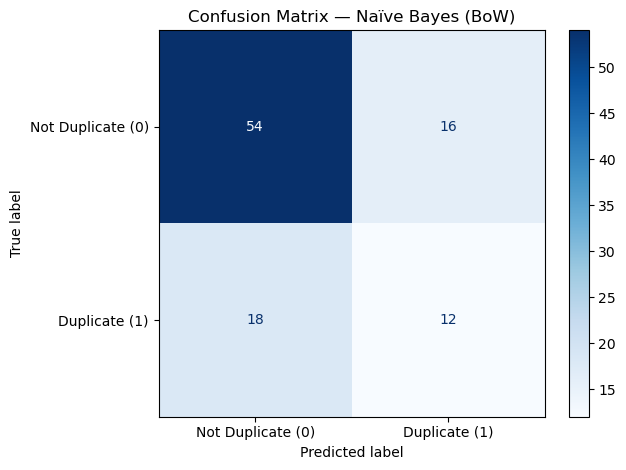

In [38]:
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix (rows=true, cols=predicted):")
print(f"               Pred 0   Pred 1")
print(f"True 0 (non-dup):  {cm[0,0]:4d}     {cm[0,1]:4d}")
print(f"True 1 (dup)    :  {cm[1,0]:4d}     {cm[1,1]:4d}")

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=["Not Duplicate (0)", "Duplicate (1)"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix — Naïve Bayes (BoW)")
plt.tight_layout()
plt.show()

In [39]:
n_neg = train_labels.count(0)
n_pos = train_labels.count(1)
print(f"\nTrain class distribution — 0: {n_neg} ({n_neg/Ntrain:.1%}), "
      f"1: {n_pos} ({n_pos/Ntrain:.1%})")


Train class distribution — 0: 648 (64.8%), 1: 352 (35.2%)


The confusion matrix shows **false negatives dominate**: 18 duplicate pairs were 
incorrectly predicted as non-duplicate, compared to 16 non-duplicates incorrectly 
predicted as duplicates. The false negative *rate* is much higher — 18 out of 30 
actual duplicates were missed (60%), versus only 16 out of 70 non-duplicates 
misclassified (23%).

This is likely driven by two factors. First, the training set is imbalanced 
(64.8% non-duplicate), which biases the model toward predicting class 0. Second, 
Bag-of-Words ignores word order and semantics — two questions that mean the same 
thing but use different vocabulary will appear dissimilar to the model, causing 
it to miss duplicate pairs.

---

### Task 4. Siamese Neural Network (7 marks)

You now want to learn semantic similarity directly from the question pairs.

1. Design a Siamese Neural Network with two identical LSTM encoders that embed each question. (3 marks)

1. Use cosine similarity to classify duplicates, and report accuracy and F1-score. (2 marks)

1. Compare your Siamese model to your Naïve Bayes model. Which one handles imbalanced errors (precision vs. recall) better in your results, and why do you think that is? (2 marks)

**Note: Use the same reduced training and test subsets that you selected/used for Task 3.**

In [40]:
# --- parameters ---
VOCAB_SIZE_THRESHOLD = 5000
MAX_LEN              = 50
BATCH_SIZE           = 32
EMBED_DIM            = 128
LSTM_HIDDEN_DIM      = 128
SIAMESE_EPOCHS       = 10
SIAMESE_LR           = 1e-3
COSINE_MARGIN        = 0.0

In [41]:
# --- Tokenizer ---
TOKENIZER_NAME = "bert-base-uncased"
TOKENIZER = BertTokenizer.from_pretrained(TOKENIZER_NAME)
VOCAB_SIZE = TOKENIZER.vocab_size
PAD_TOKEN_ID = TOKENIZER.pad_token_id

In [ ]:
def tokenizer(text):
   return text.lower().split()

class Vocabulary:
   def __init__(self):
      self.itos = {0: "<PAD>", 1: "<UNK>"}  
      self.stoi = {"<PAD>": 0, "<UNK>": 1} 

   def __len__(self):
      return len(self.itos)

   def build_vocabulary(self, sentence_list):
      word_counts = Counter()
      for sentence in sentence_list:
         word_counts.update(tokenizer(sentence))

      idx = 2
      sorted_words = sorted(word_counts.items(), key=lambda x: x[1], reverse=True)

      for word, count in sorted_words: 
         if len(self.stoi) < VOCAB_SIZE_THRESHOLD + 2: 
            self.stoi[word] = idx
            self.itos[idx] = word
            idx += 1
         else:
            break

   def numericalize(self, text):
      tokenized_text = tokenizer(text)
      return [self.stoi.get(token, self.stoi["<UNK>"]) for token in tokenized_text] 
   
class PairDataset(Dataset):
    def __init__(self, q1s, q2s, labels, vocab, max_len):
        self.q1s, self.q2s, self.labels = q1s, q2s, labels
        self.vocab, self.max_len = vocab, max_len

    def __len__(self):
        return len(self.labels)

    def _encode(self, text):
        ids = self.vocab.numericalize(text)
        if len(ids) < self.max_len:
            ids = ids + [self.vocab.stoi['<PAD>']] * (self.max_len - len(ids))
        else:
            ids = ids[:self.max_len]
        return torch.tensor(ids, dtype=torch.long)

    def __getitem__(self, idx):
        return {
            'ids1':   self._encode(self.q1s[idx]),
            'ids2':   self._encode(self.q2s[idx]),
            'labels': torch.tensor(float(self.labels[idx]), dtype=torch.float),
        }
    
vocab = Vocabulary()
vocab.build_vocabulary(q1_tr + q2_tr)
PAD_IDX = vocab.stoi['<PAD>']
print(f'Vocabulary size: {len(vocab)}')

train_dataset = PairDataset(q1_tr, q2_tr, y_tr, vocab, MAX_LEN)
test_dataset  = PairDataset(q1_te,  q2_te,  y_te,  vocab, MAX_LEN)
train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader   = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

Vocabulary size: 5002


In [ ]:
# --- Siamese Network Model ---
class SiameseNetwork(nn.Module):
    def __init__(self, vocab_size, embed_size, lstm_units, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embed_size, lstm_units, bidirectional=True, batch_first=True, num_layers=1)

    def forward_once(self, ids):
        embedded = self.embedding(ids)
        _, (h_n, _) = self.lstm(embedded)
        hidden_out = torch.cat((h_n[0,:,:], h_n[1,:,:]), 1)
        return hidden_out

    def forward(self, ids1, ids2):
        encoded1 = self.forward_once(ids1)
        encoded2 = self.forward_once(ids2)
        return nn.functional.cosine_similarity(encoded1, encoded2)


In [44]:
# --- Training and Evaluation Functions ---
def train_siamese_epoch(model, iterator, optimizer, criterion, device):
    epoch_loss = 0
    model.train()

    for batch in tqdm(iterator, total=len(iterator)):
        ids1 = batch['ids1'].to(device)
        ids2 = batch['ids2'].to(device)
        labels = batch['labels'].to(device)
        # CosineEmbeddingLoss expects raw embeddings, so call forward_once directly
        cos_target = labels * 2.0 - 1.0

        e1 = model.forward_once(ids1)
        e2 = model.forward_once(ids2)

        optimizer.zero_grad()
        loss = criterion(e1, e2, cos_target)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    return epoch_loss / len(iterator)

@torch.no_grad()
def collect_cosines(model, loader, device):
    model.eval()
    all_cos, all_y = [], []
    for batch in loader:
        ids1 = batch['ids1'].to(device)
        ids2 = batch['ids2'].to(device)
        labels = batch['labels']
        cos = model(ids1, ids2).cpu().numpy()
        all_cos.append(cos)
        all_y.append(labels.numpy().astype(int))
    return np.concatenate(all_cos), np.concatenate(all_y)

In [45]:
def evaluate_siamese_epoch(model, iterator, criterion, device):
    all_cos, all_y = [], []
    model.eval()

    with torch.no_grad():
        for batch in tqdm(iterator, total=len(iterator)):
            ids1 = batch['ids1'].to(device)
            ids2 = batch['ids2'].to(device)
            labels = batch['labels']

            cos = model(ids1, ids2).cpu().numpy()
            all_cos.append(cos)
            all_y.append(labels.numpy().astype(int))

    return np.concatenate(all_cos), np.concatenate(all_y)

In [46]:
siamese_model = SiameseNetwork(
    vocab_size=len(vocab),
    embed_size=EMBED_DIM,
    lstm_units=LSTM_HIDDEN_DIM,
    pad_idx=PAD_IDX,
).to(DEVICE)

criterion = nn.CosineEmbeddingLoss(margin=COSINE_MARGIN).to(DEVICE)
optimizer = optim.Adam(siamese_model.parameters(), lr=SIAMESE_LR)

for epoch in range(SIAMESE_EPOCHS):
    train_loss = train_siamese_epoch(siamese_model, train_loader, optimizer, criterion, DEVICE)
    print(f'Epoch {epoch + 1:02}/{SIAMESE_EPOCHS} | Train Loss: {train_loss:.4f}')

100%|██████████| 32/32 [00:01<00:00, 20.38it/s]


Epoch 01/10 | Train Loss: 0.4324


100%|██████████| 32/32 [00:01<00:00, 16.28it/s]


Epoch 02/10 | Train Loss: 0.3654


100%|██████████| 32/32 [00:01<00:00, 17.67it/s]


...

Epoch 08/10 | Train Loss: 0.1224


100%|██████████| 32/32 [00:01<00:00, 23.66it/s]


Epoch 09/10 | Train Loss: 0.1034


100%|██████████| 32/32 [00:01<00:00, 23.08it/s]

Epoch 10/10 | Train Loss: 0.0767


In [47]:
train_cos, train_y_arr = collect_cosines(siamese_model, train_loader, DEVICE)

print('Cosine sim distribution on train set:')
print(f'  Duplicates    : mean={train_cos[train_y_arr == 1].mean():+.3f}, '
      f'std={train_cos[train_y_arr == 1].std():.3f}')
print(f'  Non-duplicates: mean={train_cos[train_y_arr == 0].mean():+.3f}, '
      f'std={train_cos[train_y_arr == 0].std():.3f}')

candidate_thresholds = np.arange(-0.5, 0.91, 0.05)
best_threshold, best_f1 = 0.0, -1.0
for t in candidate_thresholds:
    preds_t = (train_cos > t).astype(int)
    f1_t = f1_score(train_y_arr, preds_t, zero_division=0)
    if f1_t > best_f1:
        best_f1, best_threshold = f1_t, t

print(f'\nBest threshold on train set : {best_threshold:+.2f} (train F1 = {best_f1:.4f})')

Cosine sim distribution on train set:
  Duplicates    : mean=+0.918, std=0.074
  Non-duplicates: mean=-0.158, std=0.301

Best threshold on train set : +0.60 (train F1 = 0.9564)


Siamese LSTM (fixed) — Test Set Metrics
  Threshold: +0.60
  Accuracy : 0.4600
  Precision: 0.2857
  Recall   : 0.5333
  F1-Score : 0.3721
  TN=30  FP=40  FN=14  TP=16


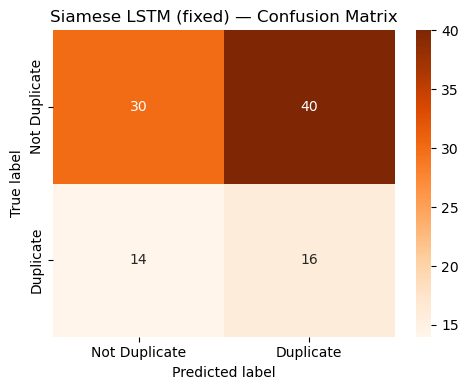

In [48]:
test_cos, test_y_arr = collect_cosines(siamese_model, test_loader, DEVICE)
siam_preds = (test_cos > best_threshold).astype(int)

siam_accuracy  = accuracy_score(test_y_arr, siam_preds)
siam_precision = precision_score(test_y_arr, siam_preds, zero_division=0)
siam_recall    = recall_score(test_y_arr, siam_preds, zero_division=0)
siam_f1        = f1_score(test_y_arr, siam_preds, zero_division=0)

print('Siamese LSTM (fixed) — Test Set Metrics')
print(f'  Threshold: {best_threshold:+.2f}')
print(f'  Accuracy : {siam_accuracy:.4f}')
print(f'  Precision: {siam_precision:.4f}')
print(f'  Recall   : {siam_recall:.4f}')
print(f'  F1-Score : {siam_f1:.4f}')

cm_siam = confusion_matrix(test_y_arr, siam_preds)
tn_s, fp_s, fn_s, tp_s = cm_siam.ravel()
print(f'  TN={tn_s}  FP={fp_s}  FN={fn_s}  TP={tp_s}')

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_siam, annot=True, fmt='d', cmap='Oranges', ax=ax,
            xticklabels=['Not Duplicate', 'Duplicate'],
            yticklabels=['Not Duplicate', 'Duplicate'])
ax.set_title('Siamese LSTM (fixed) — Confusion Matrix')
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
plt.tight_layout()
plt.show()

## Naïve Bayes and Siamese LSTM
Saved evaluation: Naïve Bayes precision 0.4286, recall 0.4000, F1 0.4138 (derived from confusion matrix); LSTM precision 0.2857, recall 0.5333, F1 0.3721. The LSTM found more duplicates but produced more false positives. These metrics do not by themselves explain how the model represents meaning.


### Task 5. Transformer-Based Classifier (10 marks)

Instead of handcrafted features or LSTMs, you now fine-tune a pre-trained Transformer (e.g., BERT or RoBERTa, etc) for QQP.

1. Fine-tune the model for 3 epochs with learning rate 2e-5. (3 marks)

1. Report the accuracy, precision, recall, and F1-score. (2 marks)

1. Compare your Transformer results with your Siamese model. Did the Transformer improve both precision and recall, or mainly one? What does this suggest about how it captures question meaning? (2 marks)

1. Look at one example your Transformer misclassified. Write a short explanation of why the model might have made this mistake. (3 marks)

**Note: Use the same reduced training and test subsets that you selected/used for Task 3.**

In [49]:
class QQPBertDataset(Dataset):
    def __init__(self, q1s, q2s, labels, tokenizer, max_len=128):
        self.q1s, self.q2s, self.labels = q1s, q2s, labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.q1s[idx], self.q2s[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids':      enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'label':          torch.tensor(self.labels[idx], dtype=torch.long)
        }

In [50]:
BERT_MAX_LEN   = 128
BERT_BATCH     = 16
BERT_EPOCHS    = 3
BERT_LR        = 2e-5

bert_train_ds = QQPBertDataset(q1_tr, q2_tr, list(y_tr), TOKENIZER, BERT_MAX_LEN)
bert_test_ds  = QQPBertDataset(q1_te, q2_te, list(y_te), TOKENIZER, BERT_MAX_LEN)
bert_train_loader = DataLoader(bert_train_ds, batch_size=BERT_BATCH, shuffle=True)
bert_test_loader  = DataLoader(bert_test_ds,  batch_size=BERT_BATCH, shuffle=False)

In [51]:
bert_model = BertForSequenceClassification.from_pretrained(
    'bert-base-uncased', num_labels=2
).to(DEVICE)

bert_optimizer = AdamW(bert_model.parameters(), lr=BERT_LR)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [52]:
for epoch in range(BERT_EPOCHS):
    bert_model.train()
    total_loss = 0
    for batch in tqdm(bert_train_loader):
        input_ids      = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        labels         = batch['label'].to(DEVICE)

        bert_optimizer.zero_grad()
        outputs = bert_model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        loss.backward()
        bert_optimizer.step()
        total_loss += loss.item()

    print(f'Epoch {epoch+1}/{BERT_EPOCHS} | Loss: {total_loss/len(bert_train_loader):.4f}')

100%|██████████| 63/63 [03:03<00:00,  2.91s/it]


Epoch 1/3 | Loss: 0.6146


100%|██████████| 63/63 [03:06<00:00,  2.96s/it]


Epoch 2/3 | Loss: 0.4740


100%|██████████| 63/63 [03:17<00:00,  3.14s/it]

Epoch 3/3 | Loss: 0.3238


In [53]:
bert_model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for batch in bert_test_loader:
        input_ids      = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        labels         = batch['label']

        outputs = bert_model(input_ids=input_ids, attention_mask=attention_mask)
        preds = outputs.logits.argmax(dim=-1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(f"Accuracy : {accuracy_score(all_labels, all_preds):.4f}")
print(f"Precision: {precision_score(all_labels, all_preds, zero_division=0):.4f}")
print(f"Recall   : {recall_score(all_labels, all_preds, zero_division=0):.4f}")
print(f"F1-Score : {f1_score(all_labels, all_preds, zero_division=0):.4f}")

Accuracy : 0.7500
Precision: 0.5758
Recall   : 0.6333
F1-Score : 0.6032


## Model comparison
Saved evaluation: LSTM accuracy 0.4600, precision 0.2857, recall 0.5333, F1 0.3721. BERT accuracy 0.7500, precision 0.5758, recall 0.6333, F1 0.6032. BERT improved precision and recall in this run. Only 100 evaluation pairs were used; the LSTM threshold was tuned on training data. Larger samples and separate validation are needed. A majority-class prediction scores 70% accuracy on this evaluation sample.


In [59]:
count = 0
for i, (pred, true) in enumerate(zip(all_preds, all_labels)):
    if pred != true:
        print(f"Index {i} | True: {true} | Pred: {pred}")
        print(f"  Q1: {q1_te[i]}")
        print(f"  Q2: {q2_te[i]}\n")
        count += 1
        if count == 5:
            break

Index 5 | True: 1 | Pred: 0
  Q1: I am 25 year old guy and never had a girlfriend. Is this weird?
  Q2: I am 25 years old. I have never had a girlfriend. Is something wrong with me?

Index 6 | True: 1 | Pred: 0
  Q1: "What does a good answer on Quora look like? What does it mean to ""be helpful""?"
  Q2: How do you write a good answer on Quora?

Index 19 | True: 1 | Pred: 0
  Q1: Is it a bad time to buy a condo or a house in the Bay Area in 2017?
  Q2: Would 2017 be a good time to buy a house in Bay Area?

Index 20 | True: 0 | Pred: 1
  Q1: How is vanilla extract made?
  Q2: How do you make sugar cookies without vanilla extract?

Index 22 | True: 0 | Pred: 1
  Q1: Why was the Roman Empire so successful?
  Q2: What are some of the rarely known facts about the Roman Empire?



## Misclassified example
BERT incorrectly labelled these as duplicates: “How is vanilla extract made?” and “How do you make sugar cookies without vanilla extract?” Shared vocabulary may have contributed, although the questions request different information. This output alone does not establish the model’s internal attention or reasoning.


---
## Use of AI generators in this assignment

**Tool used:** Claude


Task 4

**What part of the code is based on AI output:**
The evaluation helper functions `collect_cosines` and `evaluate_siamese_epoch` were updated with AI assistance. Specifically, the manual `forward_once` + `cosine_similarity` calls inside those functions were replaced with a single call to `model(ids1, ids2)` so that the model's `forward` method is actually exercised during evaluation. The unused `cal_l1_distance` helper (a leftover from an earlier draft) was also removed with AI assistance.

**Prompts used:** "The `forward()` method is never called during evaluation — the evaluation functions duplicate the cosine computation manually. Fix `collect_cosines` and `evaluate_siamese_epoch` to call `model(ids1, ids2)` instead, and remove the dead `cal_l1_distance` function."

**Modifications made:**
The core network architecture (`SiameseNetwork`), the training loop, the threshold search, and all written analysis were written by me. AI only cleaned up the two evaluation helper functions and removed dead code.

Task 5

**What part of the code is based on AI output:**
AI assisted with resolving an import error when loading `BertTokenizer` and `BertForSequenceClassification` from `transformers`, and `AdamW` from `torch.optim`.

**Prompts used:** "I'm getting an import error with `BertTokenizer`, `BertForSequenceClassification`, and `AdamW` — how do I correctly import them?"

**Modifications made:**
The `QQPBertDataset` class, the fine-tuning loop, the evaluation code, and all written analysis were written by me. AI only resolved the package import issue.